# Лабораторная работа 1. Линейная регрессия и факторный анализ

**Цель работы:** изучение основ линейной регрессии, построение простейших моделей регрессии, обучение модели на реальных данных и оценка её качества.

**Датасет:** [Auto MPG](https://www.kaggle.com/datasets/uciml/autompg-dataset) (Kaggle) — характеристики автомобилей 1970–1982 годов выпуска.

**Задача:** предсказать `mpg` (сколько миль автомобиль проезжает на одном галлоне топлива) по его техническим характеристикам. Целевая переменная непрерывная, поэтому решается задача регрессии, логистическая регрессия не нужна.

## 1. Загрузка датасета

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, KFold
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_percentage_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

df = pd.read_csv('auto-mpg.csv')
print('Размер датасета:', df.shape)
df.head()

Размер датасета: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


В датасете 398 автомобилей и 9 столбцов:

| Столбец | Описание |
|---|---|
| `mpg` | миль на галлон топлива — **целевая переменная** |
| `cylinders` | число цилиндров |
| `displacement` | объём двигателя, куб. дюймы |
| `horsepower` | мощность, л. с. |
| `weight` | масса, фунты |
| `acceleration` | время разгона до 60 миль/ч, с |
| `model year` | год выпуска (две последние цифры) |
| `origin` | регион производства: 1 — США, 2 — Европа, 3 — Япония (категориальный) |
| `car name` | название модели |

## 2. Первичный анализ данных

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    str    
dtypes: float64(3), int64(4), str(2)
memory usage: 28.1 KB


Значений `NaN` в таблице нет, но столбец `horsepower` имеет строковый тип, хотя мощность — это число. Значит, в нём есть нечисловые значения, которые нужно найти.

In [3]:
print('Нечисловые значения в horsepower:', df.loc[~df['horsepower'].str.isdigit(), 'horsepower'].unique().tolist())

df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')
df.isna().sum()

Нечисловые значения в horsepower: ['?']


mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

В `horsepower` пропуски записаны символом `?`. После преобразования столбца в числовой тип они стали `NaN`: всего 6 пропусков. В остальных столбцах пропусков нет.

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.51,7.82,9.0,17.50,23.0,29.00,46.6
cylinders,398.0,5.45,1.70,3.0,4.00,4.0,8.00,8.0
displacement,398.0,193.43,104.27,68.0,104.25,148.5,262.00,455.0
horsepower,392.0,104.47,38.49,46.0,75.00,93.5,126.00,230.0
weight,398.0,2970.42,846.84,1613.0,2223.75,2803.5,3608.00,5140.0
acceleration,398.0,15.57,2.76,8.0,13.82,15.5,17.18,24.8
model year,398.0,76.01,3.70,70.0,73.00,76.0,79.00,82.0
origin,398.0,1.57,0.80,1.0,1.00,1.0,2.00,3.0


Целевая переменная `mpg` меняется от 9 до 46.6, среднее 23.5, медиана 23. Признаки измерены в очень разных масштабах: `weight` — тысячи (1613–5140), `displacement` — сотни, `cylinders` — единицы (3–8). Поэтому перед Lasso, Ridge и PCA данные нужно стандартизировать.

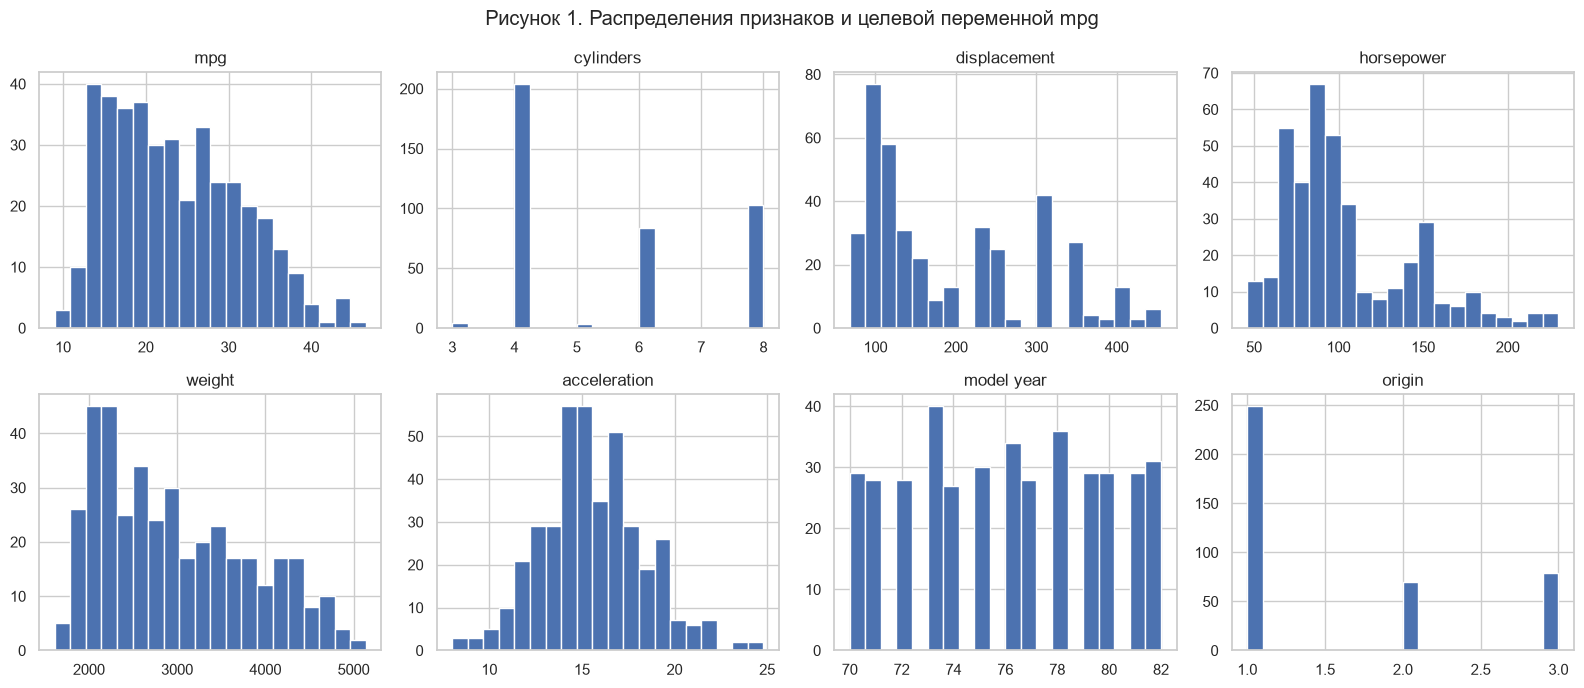

In [5]:
df.drop(columns='car name').hist(bins=20, figsize=(16, 7), layout=(2, 4))
plt.suptitle('Рисунок 1. Распределения признаков и целевой переменной mpg')
plt.tight_layout()
plt.show()

**Рисунок 1:**

- `mpg` скошена вправо: больше всего автомобилей с 13–20 mpg, экономичных (выше 35) мало;
- `displacement`, `horsepower` и `weight` тоже скошены вправо — тяжёлых и мощных автомобилей меньшинство;
- `acceleration` распределён почти симметрично вокруг 15.5 с;
- `cylinders` дискретный: почти все автомобили имеют 4, 6 или 8 цилиндров;
- `model year` распределён примерно равномерно;
- `origin` — три категории, больше всего автомобилей из США (около 250 из 398).

## 3. Предобработка данных

Удаляем строки с пропусками, убираем `car name` и кодируем категориальный признак `origin`.

In [6]:
df = df.dropna().drop(columns='car name')
df['origin'] = df['origin'].map({1: 'USA', 2: 'Europe', 3: 'Japan'})
df = pd.get_dummies(df, columns=['origin'], drop_first=True, dtype=int)

print('Размер после предобработки:', df.shape)
df.head()

Размер после предобработки: (392, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin_Japan,origin_USA
0,18.0,8,307.0,130.0,3504,12.0,70,0,1
1,15.0,8,350.0,165.0,3693,11.5,70,0,1
2,18.0,8,318.0,150.0,3436,11.0,70,0,1
3,16.0,8,304.0,150.0,3433,12.0,70,0,1
4,17.0,8,302.0,140.0,3449,10.5,70,0,1


- Удалено 6 строк с пропусками (1.5% выборки), осталось 392 автомобиля.
- `car name` удалён: это текстовое название модели, почти уникальное для каждой строки, числовой информации для регрессии в нём нет.
- `origin` закодирован one-hot: числа 1, 2, 3 — это метки регионов, а не величина, и модель не должна считать, что Япония «в три раза больше» США. Получились признаки `origin_Japan` и `origin_USA`. Европа выбрана базовой категорией (`drop_first=True`): если оставить все три столбца, их сумма всегда равна 1, и это создаёт точную линейную зависимость между признаками.

В итоге 8 признаков и целевая переменная.

## 4. Матрица корреляций и мультиколлинеарность

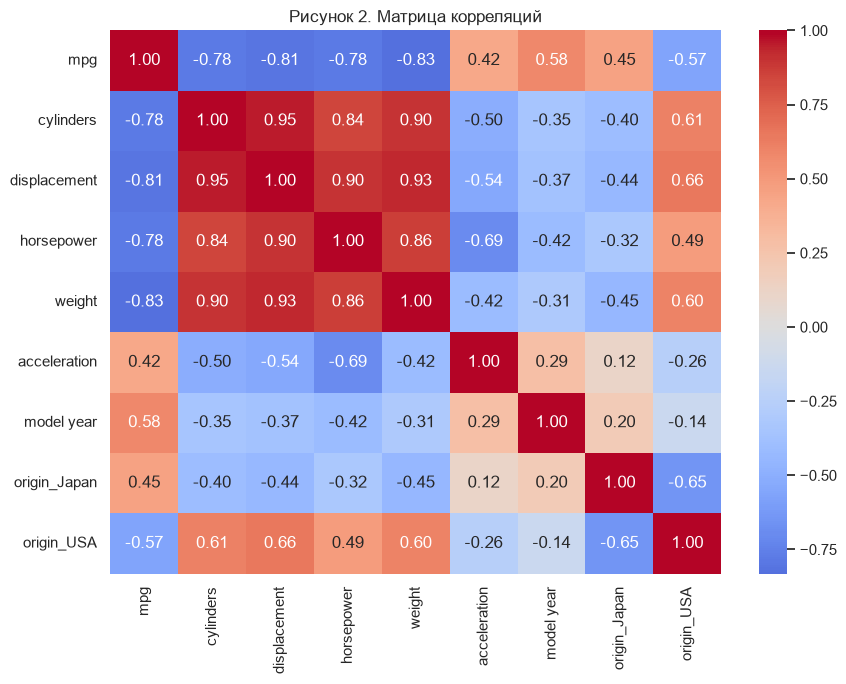

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Рисунок 2. Матрица корреляций')
plt.tight_layout()
plt.show()

**Рисунок 2:**

- `mpg` сильно отрицательно связана с `weight` (−0.83), `displacement` (−0.81), `cylinders` (−0.78) и `horsepower` (−0.78): чем тяжелее и мощнее автомобиль, тем меньше он проезжает на галлоне топлива.
- С `model year` связь положительная и умеренная (0.58): более новые автомобили экономичнее.
- Признаки `cylinders`, `displacement`, `horsepower` и `weight` очень сильно коррелируют между собой (от 0.84 до 0.95). Это признак мультиколлинеарности: четыре признака несут почти одну и ту же информацию о размере и мощности автомобиля.

Проверим это количественно с помощью VIF. Коэффициент VIF показывает, насколько признак линейно выражается через остальные: $VIF_j = \dfrac{1}{1 - R_j^2}$, где $R_j^2$ — коэффициент детерминации регрессии $j$-го признака на все остальные. Обычно VIF выше 5 считают заметной мультиколлинеарностью, выше 10 — сильной.

In [8]:
X = df.drop(columns='mpg')
y = df['mpg']


def calc_vif(X):
    """VIF каждого признака; константа добавляется, чтобы расчёт был корректным."""
    X_const = X.assign(const=1.0).values
    vif = [variance_inflation_factor(X_const, i) for i in range(X.shape[1])]
    return pd.DataFrame({'VIF': vif}, index=X.columns).round(2)


calc_vif(X)

,VIF
cylinders,10.74
displacement,22.94
horsepower,9.96
weight,11.07
acceleration,2.63
model year,1.30
origin_Japan,1.85
origin_USA,2.70


Мультиколлинеарность есть, и она сильная:

- у `displacement` VIF = 22.9 — намного выше порога 10;
- у `weight` (11.1) и `cylinders` (10.7) VIF немного выше 10, у `horsepower` (9.96) — на самой границе;
- у остальных признаков VIF меньше 3, проблем нет.

Это та же группа из четырёх признаков, что выделялась на матрице корреляций. Из-за мультиколлинеарности коэффициенты обычной линейной регрессии при этих признаках оцениваются неустойчиво и плохо интерпретируются. Способы борьбы — регуляризация (Lasso, Ridge) и переход к главным компонентам (PCA).

## 5. Регрессионные модели на исходных признаках

Строим три модели: обычную линейную регрессию, Lasso (штраф L1 на коэффициенты) и Ridge (штраф L2).

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка: ', X_test.shape)

Обучающая выборка: (313, 8)
Тестовая выборка:  (79, 8)


Выборка разделена в соотношении 80/20: 313 автомобилей для обучения и 79 для теста.

Признаки стандартизированы (среднее 0, стандартное отклонение 1). Это нужно, потому что штраф в Lasso и Ridge зависит от величины коэффициентов, а она зависит от масштаба признака; PCA тоже чувствителен к масштабу. Параметры стандартизации вычислены только по обучающей выборке, чтобы информация из тестовой не попадала в обучение.

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alphas = np.logspace(-3, 2, 50)


def best_alpha(model, X_tr):
    """Подбор коэффициента регуляризации alpha по кросс-валидации (минимум RMSE)."""
    search = GridSearchCV(model, {'alpha': alphas}, cv=cv, scoring='neg_root_mean_squared_error')
    return search.fit(X_tr, y_train).best_params_['alpha']


def evaluate(models, X_tr, X_te):
    """Метрики каждой модели: средние по кросс-валидации и на тестовой выборке."""
    scoring = {'rmse': 'neg_root_mean_squared_error', 'r2': 'r2', 'mape': 'neg_mean_absolute_percentage_error'}
    rows = {}
    for name, model in models.items():
        scores = cross_validate(model, X_tr, y_train, cv=cv, scoring=scoring)
        pred = model.fit(X_tr, y_train).predict(X_te)
        rows[name] = {
            'RMSE (CV)': -scores['test_rmse'].mean(),
            'R² (CV)': scores['test_r2'].mean(),
            'MAPE (CV), %': -scores['test_mape'].mean() * 100,
            'RMSE (тест)': root_mean_squared_error(y_test, pred),
            'R² (тест)': r2_score(y_test, pred),
            'MAPE (тест), %': mean_absolute_percentage_error(y_test, pred) * 100,
        }
    return pd.DataFrame(rows).T.round(3)


lasso_alpha = best_alpha(Lasso(), X_train_sc)
ridge_alpha = best_alpha(Ridge(), X_train_sc)
print(f'alpha для Lasso: {lasso_alpha:.4f}')
print(f'alpha для Ridge: {ridge_alpha:.4f}')

alpha для Lasso: 0.0133
alpha для Ridge: 2.9471


Параметр `alpha` задаёт силу штрафа: при `alpha = 0` Lasso и Ridge совпадают с обычной линейной регрессией, чем он больше, тем сильнее коэффициенты прижимаются к нулю. Значение подобрано перебором 50 вариантов от 0.001 до 100 с помощью 5-кратной кросс-валидации на обучающей выборке.

Оптимальные значения небольшие: 0.0133 для Lasso и 2.95 для Ridge. То есть сильная регуляризация здесь не нужна — наблюдений (313) намного больше, чем признаков (8), и модель не переобучается.

In [11]:
models = {
    'Linear': LinearRegression(),
    'Lasso': Lasso(alpha=lasso_alpha),
    'Ridge': Ridge(alpha=ridge_alpha),
}

results = evaluate(models, X_train_sc, X_test_sc)
results

,RMSE (CV),R² (CV),"MAPE (CV), %",RMSE (тест),R² (тест),"MAPE (тест), %"
Linear,3.367,0.819,12.197,3.256,0.792,12.039
Lasso,3.362,0.819,12.095,3.273,0.790,12.072
Ridge,3.357,0.820,11.934,3.280,0.789,12.012


Столбцы «CV» — средние значения метрик по 5 фолдам кросс-валидации на обучающей выборке, столбцы «тест» — метрики на отложенной тестовой выборке.

- **R²** на тесте ≈ 0.79, по кросс-валидации ≈ 0.82: модели объясняют около 80% разброса `mpg`.
- **RMSE** ≈ 3.3 mpg при среднем значении `mpg` 23.5.
- **MAPE** ≈ 12%: прогноз в среднем отличается от фактического значения на 12%.

Метрики на тесте близки к метрикам кросс-валидации, значит, переобучения нет. Все три модели дают практически одинаковое качество: различия в RMSE не превышают 0.03 mpg. По кросс-валидации чуть лучше Ridge, на тесте — обычная линейная регрессия, но эта разница несущественна. Регуляризация почти не меняет точность прогноза; её влияние видно на коэффициентах.

In [12]:
pd.DataFrame({name: model.coef_ for name, model in models.items()}, index=X.columns).round(3)

,Linear,Lasso,Ridge
cylinders,-0.581,-0.295,-0.445
displacement,1.990,1.370,1.306
horsepower,-0.826,-0.730,-0.914
weight,-5.394,-5.211,-4.859
acceleration,0.119,0.084,0.015
model year,2.889,2.860,2.814
origin_Japan,0.133,0.136,0.195
origin_USA,-1.376,-1.296,-1.269


Коэффициенты получены на стандартизированных признаках, поэтому их можно сравнивать по модулю. Сильнее всего на `mpg` влияют `weight` (около −5: тяжёлые автомобили менее экономичны) и `model year` (около +2.9: новые экономичнее).

Влияние мультиколлинеарности видно на `displacement`: корреляция этого признака с `mpg` отрицательная (−0.81), а коэффициент в модели положительный (+1.99). Знак «перевернулся», потому что ту же информацию уже несут `weight`, `cylinders` и `horsepower`, и модель не может надёжно разделить их вклады.

Регуляризация уменьшает такие неустойчивые коэффициенты: у `displacement` с 1.99 до 1.37 (Lasso) и 1.31 (Ridge), у `cylinders` с −0.58 до −0.30 и −0.45. Ни один коэффициент Lasso не обнулился, потому что оптимальный `alpha` очень мал.

## 6. Анализ остатков

Остаток — разность между фактическим и предсказанным значением `mpg`. Если модель адекватна, остатки разбросаны вокруг нуля случайно и с одинаковым размахом при любых значениях прогноза (гомоскедастичность). Если размах остатков меняется — это гетероскедастичность.

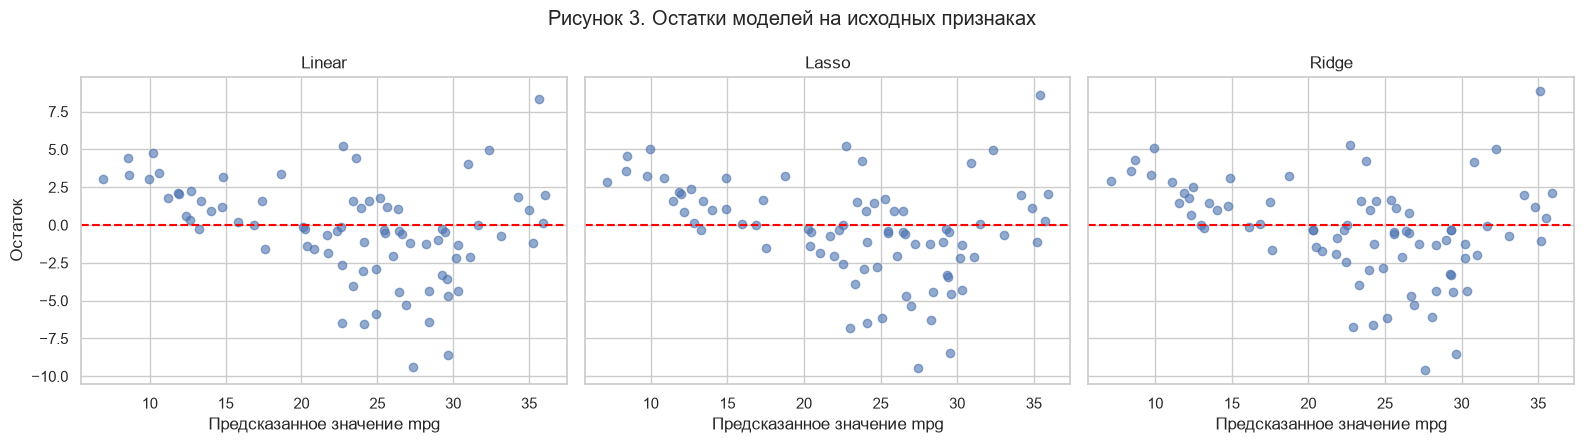

In [13]:
def plot_residuals(models, X_te, title):
    """Остатки (факт минус прогноз) на тестовой выборке против предсказанных значений."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
    for ax, (name, model) in zip(axes, models.items()):
        pred = model.predict(X_te)
        ax.scatter(pred, y_test - pred, alpha=0.6)
        ax.axhline(0, color='red', linestyle='--')
        ax.set_title(name)
        ax.set_xlabel('Предсказанное значение mpg')
    axes[0].set_ylabel('Остаток')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_residuals(models, X_test_sc, 'Рисунок 3. Остатки моделей на исходных признаках')

**Рисунок 3.** Графики трёх моделей почти совпадают, выводы для них общие.

- **Остатки гетероскедастичны.** Разброс растёт вместе с прогнозом и имеет форму «воронки»: при прогнозе ниже 15 mpg остатки лежат в узкой полосе примерно от 0 до +5, а при прогнозе 22–35 mpg — от −9 до +8. Экономичные автомобили модель предсказывает менее точно, чем неэкономичные.
- **Есть систематическая ошибка.** При малых прогнозах (ниже 15) почти все остатки положительные — модель занижает `mpg`; в середине диапазона (20–30) преобладают отрицательные — модель завышает. Остатки изгибаются дугой, а не лежат случайно вокруг нуля, значит, зависимость `mpg` от признаков не совсем линейная.

Вероятная причина: расход топлива связан с массой и мощностью нелинейно, а прямая линия такую зависимость описывает только приближённо. Гетероскедастичность не смещает сами прогнозы, но делает оценки погрешности коэффициентов ненадёжными. Улучшить модель можно преобразованием целевой переменной (например, прогнозировать `log(mpg)`) или добавлением нелинейных признаков.

## 7. Метод главных компонент (PCA)

PCA заменяет исходные коррелированные признаки новыми — главными компонентами. Каждая компонента — линейная комбинация исходных признаков; компоненты не коррелируют друг с другом и упорядочены по убыванию объясняемой дисперсии. Данные уже стандартизированы в разделе 5 — это обязательный шаг перед PCA, иначе признаки с большим масштабом (`weight`) определили бы все компоненты.

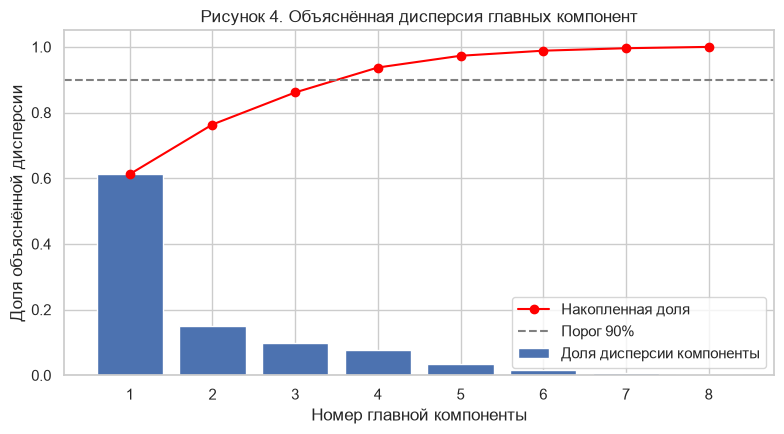

,Доля дисперсии,Накопленная доля
PC1,0.612,0.612
PC2,0.151,0.764
PC3,0.098,0.861
PC4,0.076,0.937
PC5,0.036,0.973
PC6,0.015,0.988
PC7,0.008,0.996
PC8,0.004,1.000


In [14]:
pca_full = PCA().fit(X_train_sc)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
numbers = np.arange(1, len(cum_var) + 1)

plt.figure(figsize=(8, 4.5))
plt.bar(numbers, pca_full.explained_variance_ratio_, label='Доля дисперсии компоненты')
plt.plot(numbers, cum_var, color='red', marker='o', label='Накопленная доля')
plt.axhline(0.9, color='gray', linestyle='--', label='Порог 90%')
plt.xlabel('Номер главной компоненты')
plt.ylabel('Доля объяснённой дисперсии')
plt.title('Рисунок 4. Объяснённая дисперсия главных компонент')
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({'Доля дисперсии': pca_full.explained_variance_ratio_, 'Накопленная доля': cum_var},
             index=[f'PC{i}' for i in numbers]).round(3)

**Рисунок 4.** Первая компонента объясняет 61.2% всей дисперсии признаков — это следствие сильной корреляции исходных признаков. Три компоненты объясняют 86.1%, четыре — 93.7%. Оставляем минимальное число компонент, которое объясняет не менее 90% дисперсии, то есть четыре: размерность снижается с 8 до 4 при потере 6.3% дисперсии.

In [15]:
pca = PCA(n_components=0.9)
X_train_pca = pca.fit_transform(X_train_sc)
X_test_pca = pca.transform(X_test_sc)
pc_names = [f'PC{i + 1}' for i in range(pca.n_components_)]

print('Число главных компонент:', pca.n_components_)
calc_vif(pd.DataFrame(X_train_pca, columns=pc_names))

Число главных компонент: 4


,VIF
PC1,1.0
PC2,1.0
PC3,1.0
PC4,1.0


Параметр `n_components=0.9` означает «оставить столько компонент, чтобы они объясняли не менее 90% дисперсии» — получилось 4. PCA обучен на обучающей выборке, тестовая только преобразуется.

VIF всех главных компонент равен 1 — компоненты не коррелируют между собой, **мультиколлинеарность устранена** (у исходных признаков VIF доходил до 22.9).

In [16]:
pd.DataFrame(pca.components_.T, index=X.columns, columns=pc_names).round(2)

,PC1,PC2,PC3,PC4
cylinders,0.42,0.04,0.13,0.27
displacement,0.44,0.03,0.11,0.19
horsepower,0.42,0.25,0.13,0.01
weight,0.42,-0.04,0.13,0.37
acceleration,-0.27,-0.44,-0.22,0.77
model year,-0.21,-0.37,0.88,-0.06
origin_Japan,-0.26,0.59,0.35,0.34
origin_USA,0.32,-0.51,0.01,-0.22


Таблица показывает, с какими весами исходные признаки входят в каждую компоненту:

- **PC1** — `cylinders`, `displacement`, `horsepower` и `weight` с почти равными весами (0.42–0.44). Это общий фактор «размер и мощность автомобиля»: четыре мультиколлинеарных признака собраны в одну компоненту.
- **PC2** — в основном регион производства (`origin_Japan` 0.59, `origin_USA` −0.51).
- **PC3** — год выпуска (`model year` 0.88).
- **PC4** — время разгона (`acceleration` 0.77).

## 8. Регрессионные модели на главных компонентах

Повторяем раздел 5 с теми же функциями, но вместо 8 исходных признаков используем 4 главные компоненты.

In [17]:
lasso_alpha_pca = best_alpha(Lasso(), X_train_pca)
ridge_alpha_pca = best_alpha(Ridge(), X_train_pca)
print(f'alpha для Lasso: {lasso_alpha_pca:.4f}')
print(f'alpha для Ridge: {ridge_alpha_pca:.4f}')

models_pca = {
    'Linear': LinearRegression(),
    'Lasso': Lasso(alpha=lasso_alpha_pca),
    'Ridge': Ridge(alpha=ridge_alpha_pca),
}

results_pca = evaluate(models_pca, X_train_pca, X_test_pca)
results_pca

alpha для Lasso: 0.0168
alpha для Ridge: 5.9636


,RMSE (CV),R² (CV),"MAPE (CV), %",RMSE (тест),R² (тест),"MAPE (тест), %"
Linear,3.576,0.796,11.813,3.567,0.751,12.354
Lasso,3.576,0.796,11.788,3.566,0.751,12.317
Ridge,3.575,0.796,11.763,3.558,0.752,12.262


На главных компонентах модели дают на тесте R² ≈ 0.75, RMSE ≈ 3.56 mpg и MAPE ≈ 12.3%. Метрики на тесте снова близки к кросс-валидации.

Три модели здесь практически неразличимы (RMSE на тесте 3.558–3.567). Это ожидаемо: регуляризация помогает при коррелированных признаках, а главные компоненты не коррелируют, и исправлять ей нечего.

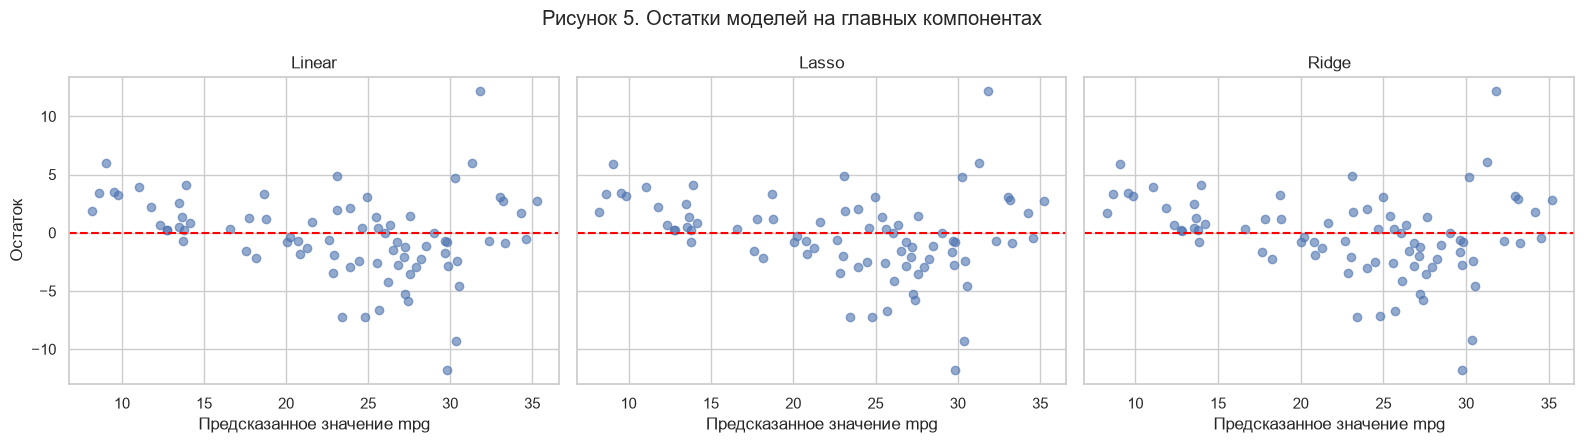

In [18]:
plot_residuals(models_pca, X_test_pca, 'Рисунок 5. Остатки моделей на главных компонентах')

**Рисунок 5.** Структура остатков та же, что и на исходных признаках: разброс растёт с ростом прогноза (гетероскедастичность), при малых прогнозах остатки в основном положительные. Размах остатков стал больше — примерно от −12 до +12. PCA устраняет мультиколлинеарность, но не нелинейность зависимости, поэтому форма остатков не изменилась.

### Сравнение моделей на исходных признаках и на главных компонентах

In [19]:
pd.concat([results, results_pca], keys=['Исходные признаки', 'Главные компоненты'])

RMSE (CV)  R² (CV)  MAPE (CV), %  RMSE (тест)  \
Исходные признаки  Linear      3.367    0.819        12.197        3.256   
                   Lasso       3.362    0.819        12.095        3.273   
                   Ridge       3.357    0.820        11.934        3.280   
Главные компоненты Linear      3.576    0.796        11.813        3.567   
                   Lasso       3.576    0.796        11.788        3.566   
                   Ridge       3.575    0.796        11.763        3.558   

                           R² (тест)  MAPE (тест), %  
Исходные признаки  Linear      0.792          12.039  
                   Lasso       0.790          12.072  
                   Ridge       0.789          12.012  
Главные компоненты Linear      0.751          12.354  
                   Lasso       0.751          12.317  
                   Ridge       0.752          12.262

- **RMSE и R² на главных компонентах хуже.** На тесте RMSE вырос с 3.26–3.28 до 3.56–3.57 mpg (примерно на 10%), R² снизился с 0.79 до 0.75. По кросс-валидации картина та же: RMSE 3.36 → 3.58, R² 0.82 → 0.80.
- **MAPE почти не изменилась:** на тесте 12.0% → 12.3%, по кросс-валидации 11.9–12.2% → 11.8%.
- **Причина ухудшения:** отброшенные 4 компоненты содержали 6.3% дисперсии признаков, и часть этой информации была полезна для прогноза. PCA выбирает компоненты по дисперсии признаков и не учитывает целевую переменную.
- **Что получено взамен:** признаков вдвое меньше (4 вместо 8), и мультиколлинеарности нет (VIF = 1 против 22.9).

Для точности прогноза на этих данных лучше модели на исходных признаках. PCA оправдан, когда важнее устойчивость коэффициентов и меньшее число признаков.

## Выводы

1. Загружен датасет Auto MPG (398 автомобилей). Удалены 6 строк с пропусками в `horsepower`, категориальный признак `origin` закодирован one-hot. Для моделей использованы 392 наблюдения и 8 признаков.
2. Матрица корреляций и VIF показали сильную мультиколлинеарность признаков `displacement` (VIF = 22.9), `weight` (11.1), `cylinders` (10.7) и `horsepower` (9.96): все они описывают размер и мощность автомобиля.
3. Линейная, Lasso и Ridge регрессии на исходных признаках (разбиение 80/20, 5-кратная кросс-валидация) дали почти одинаковое качество на тесте: RMSE ≈ 3.3 mpg, R² ≈ 0.79, MAPE ≈ 12%. Регуляризация не повысила точность, но уменьшила неустойчивые коэффициенты при коррелированных признаках.
4. Остатки гетероскедастичны: разброс растёт с ростом прогноза. Кроме того, на краях диапазона модель систематически ошибается, что говорит о нелинейности зависимости.
5. PCA после стандартизации сократил 8 признаков до 4 главных компонент (93.7% дисперсии) и полностью устранил мультиколлинеарность (VIF = 1).
6. Модели на главных компонентах немного уступают моделям на исходных признаках: RMSE ≈ 3.56 против 3.26–3.28, R² ≈ 0.75 против 0.79, MAPE ≈ 12.3% против 12.0%.

**Причины погрешности и способы повысить точность.** Основной источник ошибки — нелинейная связь `mpg` с массой и мощностью, которую линейная модель описывает приближённо; это видно по графикам остатков. Кроме того, в данных нет части факторов, влияющих на расход топлива (например, типа коробки передач). Повысить точность можно, если прогнозировать `log(mpg)` вместо `mpg` или добавить нелинейные признаки (квадраты, произведения). Усиление регуляризации точность не повысит: наблюдений намного больше, чем признаков, и модель не переобучена.